# Exploratory data analysis

Use the cleaned data to check imbalance and compare a few numeric features.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

cleaned_path = Path("../data/cleaned_data.csv.gz")
df = pd.read_csv(cleaned_path)

Class
Normal    283253
Fraud        473
Name: count, dtype: int64
Fraud transactions: 0.167%


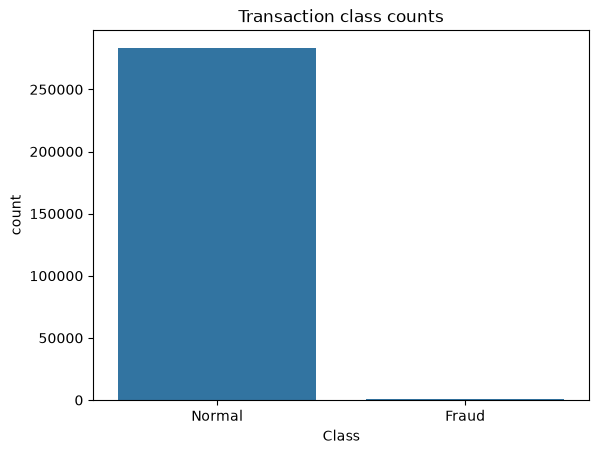

In [2]:
class_counts = df["Class"].value_counts().sort_index()
fraud_percent = 100 * class_counts.loc[1] / len(df)
print(class_counts.rename(index={0: "Normal", 1: "Fraud"}))
print(f"Fraud transactions: {fraud_percent:.3f}%")

sns.countplot(data=df, x="Class")
plt.xticks([0, 1], ["Normal", "Fraud"])
plt.title("Transaction class counts")
plt.show()

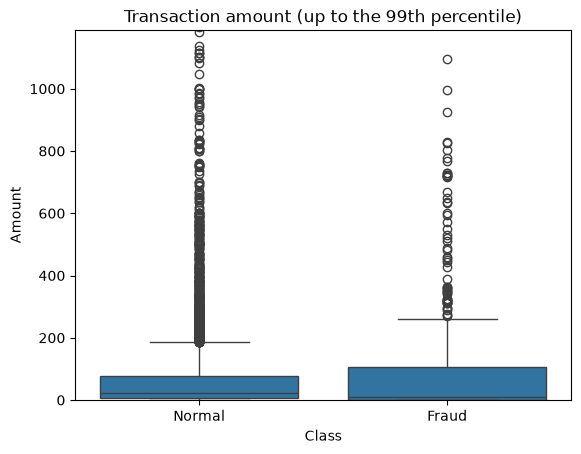

Class
0    22.00
1     9.82
Name: Amount, dtype: float64


In [3]:
# Compare amount distributions without letting the normal class dominate the plot
sample_df = pd.concat([
    df[df["Class"] == 0].sample(n=min(5000, int(class_counts.loc[0])), random_state=42),
    df[df["Class"] == 1]
])
sns.boxplot(data=sample_df, x="Class", y="Amount")
plt.xticks([0, 1], ["Normal", "Fraud"])
plt.ylim(0, sample_df["Amount"].quantile(0.99))
plt.title("Transaction amount (up to the 99th percentile)")
plt.show()
print(df.groupby("Class")["Amount"].median())

Features with the largest absolute correlation with Class: ['V17', 'V14', 'V12', 'V10']


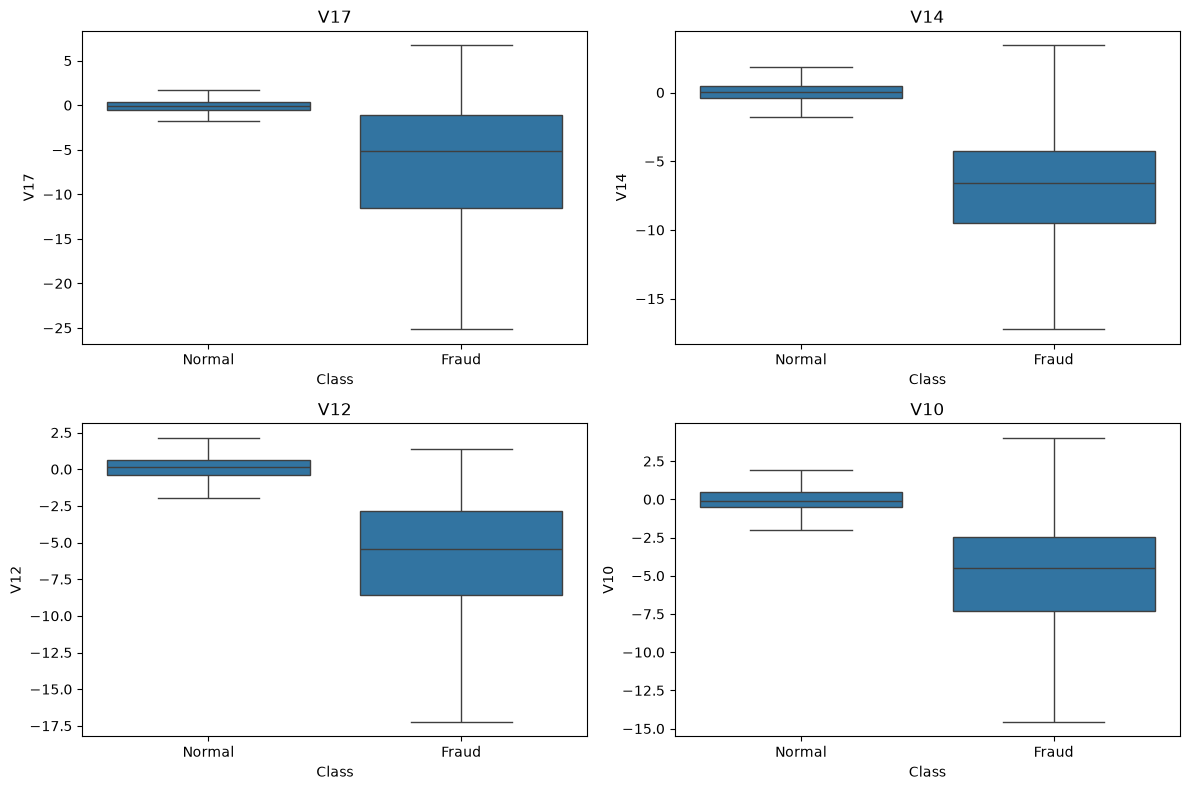

In [4]:
feature_corr = df.corr(numeric_only=True)["Class"].drop("Class").abs().sort_values(ascending=False)
top_features = feature_corr.head(4).index.tolist()
print("Features with the largest absolute correlation with Class:", top_features)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(top_features, axes.flat):
    sns.boxplot(data=df, x="Class", y=feature, showfliers=False, ax=ax)
    ax.set_xticks([0, 1], ["Normal", "Fraud"])
    ax.set_title(feature)
plt.tight_layout()
plt.show()

## Modeling notes

Fraud is rare, so accuracy by itself will hide missed fraud cases. The anonymized `V` features show differences worth testing, but their meanings are not known. I will compare precision and recall alongside F1 and ROC-AUC.